In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [ ]:
#dataset gabungan
root=Path("..")/"Experiment_Results"/"HasilEksperimenTahap2"/"Tahap2A"/"Population"
population_values=[50,100,250,500,1000]

dataframes=[];
for population in population_values:
    population_directory=root/str(population)
    for csv_file in population_directory.rglob("*.csv"):
        df=pd.read_csv(csv_file)
        df["population_folder"]=population
        df["source_path"]=str(csv_file.relative_to(root))

        dataframes.append(df)
if dataframes:
    df_all=pd.concat(dataframes, ignore_index=True)
else:
    df_all=pd.DataFrame()
print("Shape:", df_all.shape)
display(df_all.head())

Shape: (5400, 32)


,run_id,stage,experiment_id,model_id,representation,selection,crossover,mutation_operator,map_id,map_type,...,best_cost,best_fitness,evaluations_used,generations_completed,execution_time_ms,termination_reason,run_status,fs_positions,population_folder,source_path
0,Tiny_acak_3_M01_R01,HasilEksperimenTahap2,Tahap2A_Population,M01,bit,roulette,singlepoint,randommove,Tiny_acak_3,Random,...,2.714286,0.269231,3600,72,91,STAGNATION,SUCCESS,"(5,3);(1,4);(5,8)",50,50\Tiny\Tiny_acak_3\results.csv
1,Tiny_acak_3_M01_R02,HasilEksperimenTahap2,Tahap2A_Population,M01,bit,roulette,singlepoint,randommove,Tiny_acak_3,Random,...,2.714286,0.269231,5250,105,78,STAGNATION,SUCCESS,"(1,3);(5,3);(5,8)",50,50\Tiny\Tiny_acak_3\results.csv
2,Tiny_acak_3_M01_R03,HasilEksperimenTahap2,Tahap2A_Population,M01,bit,roulette,singlepoint,randommove,Tiny_acak_3,Random,...,2.857143,0.259259,3800,76,92,STAGNATION,SUCCESS,"(6,3);(2,5);(6,8)",50,50\Tiny\Tiny_acak_3\results.csv
3,Tiny_acak_3_M01_R04,HasilEksperimenTahap2,Tahap2A_Population,M01,bit,roulette,singlepoint,randommove,Tiny_acak_3,Random,...,2.785714,0.264151,4150,83,95,STAGNATION,SUCCESS,"(5,3);(3,5);(6,8)",50,50\Tiny\Tiny_acak_3\results.csv
4,Tiny_acak_3_M01_R05,HasilEksperimenTahap2,Tahap2A_Population,M01,bit,roulette,singlepoint,randommove,Tiny_acak_3,Random,...,2.785714,0.264151,6200,124,25,STAGNATION,SUCCESS,"(5,2);(1,3);(5,8)",50,50\Tiny\Tiny_acak_3\results.csv


In [ ]:
root = Path("..")/"Experiment_Results" / "HasilEksperimenTahap2" / "Tahap2A" / "Population"

population_directory = root / "50"

print("Current working directory:", Path.cwd())
print("Population directory:", population_directory.resolve())
print("Folder exists:", population_directory.exists())


Current working directory: d:\tugas-kuliah\Artificial Intelligence\FireStation_AI\analisis
Population directory: D:\tugas-kuliah\Artificial Intelligence\FireStation_AI\Experiment_Results\HasilEksperimenTahap2\Tahap2A\Population\50
Folder exists: True


In [ ]:
#best cost berdasarkan map, ukuran peta, model dan populasi
summary_population=(df_all.groupby(["grid_rows","model_id", "population", "map_type"], as_index=False).agg( mean_best_cost=("best_cost", "mean"),
        std_best_cost=("best_cost", "std"),
        total_runs=("best_cost", "count")))
display(summary_population)
#populasi 50 best cost berdasarkan model dan jenis peta
df_50 = df_all[df_all["population"] == 50]
summary_50 = (
    df_50
    .groupby(
        ["model_id", "map_type"],
        as_index=False
    )
    .agg(
        mean_best_cost=("best_cost", "mean"),
        std_best_cost=("best_cost", "std"),
        total_runs=("best_cost", "count")
    )
)

display(summary_50)

summary_pivot = summary_population.pivot(
    index=["grid_rows", "population", "model_id"],
    columns="map_type",
    values="mean_best_cost"
)

display(summary_pivot)


,grid_rows,model_id,population,map_type,mean_best_cost,std_best_cost,total_runs
0,10,M01,50,Cluster,2.530000,0.053498,30
1,10,M01,50,Maze,3.344444,0.042285,30
2,10,M01,50,Random,2.602183,0.167748,60
3,10,M01,100,Cluster,2.520000,0.040684,30
4,10,M01,100,Maze,3.350000,0.050855,30
...,...,...,...,...,...,...,...
130,40,M04,500,Maze,6.900690,0.051149,30
131,40,M04,500,Random,6.690134,0.114609,60
132,40,M04,1000,Cluster,5.493333,0.035810,30
133,40,M04,1000,Maze,6.893793,0.037582,30


,model_id,map_type,mean_best_cost,std_best_cost,total_runs
0,M01,Cluster,4.278701,1.277287,90
1,M01,Maze,5.682374,1.663252,90
2,M01,Random,5.187847,1.848956,180
3,M03,Cluster,4.277101,1.281946,90
4,M03,Maze,5.687969,1.659800,90
5,M03,Random,5.187953,1.845745,180
6,M04,Cluster,4.308503,1.318883,90
7,M04,Maze,5.719760,1.666909,90
8,M04,Random,5.203133,1.860812,180


map_type                        Cluster      Maze    Random
grid_rows population model_id                              
10        50         M01       2.530000  3.344444  2.602183
                     M03       2.523333  3.355556  2.607143
                     M04       2.500000  3.377778  2.601984
          100        M01       2.520000  3.350000  2.589683
                     M03       2.523333  3.344444  2.586111
                     M04       2.500000  3.338889  2.596429
          250        M01       2.503333  3.338889  2.570238
                     M03       2.500000  3.338889  2.576984
                     M04       2.500000  3.350000  2.573016
          500        M01       2.516667  3.333333  2.598810
                     M03       2.516667  3.344444  2.614286
                     M04       2.500000  3.333333  2.596032
          1000       M01       2.536667  3.344444  2.654960
                     M03       2.570000  3.344444  2.657937
                     M04       2.506667  3.338889  2.653571
20        50         M01       4.801802  6.816239  6.267511
                     M03       4.795495  6.811111  6.266741
                     M04       4.864865  6.858974  6.285759
          100        M01       4.801802  6.826496  6.260801
                     M03       4.797297  6.817094  6.260887
                     M04       4.822523  6.827350  6.285865
          250        M01       4.796396  6.817094  6.254979
                     M03       4.798198  6.810256  6.248750
                     M04       4.800901  6.819658  6.259637
          500        M01       4.799099  6.818803  6.249551
                     M03       4.792793  6.808547  6.248301
                     M04       4.791892  6.812821  6.251282
          1000       M01       4.804505  6.811111  6.244519
                     M03       4.783784  6.805128  6.244936
                     M04       4.786486  6.805128  6.244947
40        50         M01       5.504301  6.886437  6.693849
                     M03       5.512473  6.897241  6.689976
                     M04       5.560645  6.922529  6.721656
          100        M01       5.499140  6.895402  6.697601
                     M03       5.505161  6.901379  6.691018
                     M04       5.574409  6.925287  6.713162
          250        M01       5.511398  6.900920  6.698403
                     M03       5.506882  6.887126  6.674618
                     M04       5.518925  6.908736  6.695291
          500        M01       5.491828  6.905747  6.682759
                     M03       5.483656  6.875862  6.690272
                     M04       5.510108  6.900690  6.690134
          1000       M01       5.493118  6.920230  6.689423
                     M03       5.469247  6.873103  6.664776
                     M04       5.493333  6.893793  6.682778

In [9]:
#filter by model
#model 1
df_m01=df_all[df_all["model_id"]=="M01"].copy()
#avg best cost model 1 berdasarkan populasi dan jenis 
summary_M01=(df_m01.groupby(["population", "map_type"], as_index=False).agg(
        mean_cost=("best_cost", "mean"),
        best_run=("best_cost", "min"),
        worst_run=("best_cost", "max"),
        std_cost=("best_cost", "std"),
        total_runs=("best_cost", "count")
    ))
display(summary_M01)

# model 1 per map
table_random = (
    summary_M01[summary_M01["map_type"] == "Random"]
    .sort_values("population")
)

display(table_random)
table_maze = (
    summary_M01[summary_M01["map_type"] == "Maze"]
    .sort_values("population")
)

display(table_maze)
table_cluster = (
    summary_M01[summary_M01["map_type"] == "Cluster"]
    .sort_values("population")
)

display(table_cluster)


,population,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,50,Cluster,4.278701,2.500000,5.696774,1.277287,90
1,50,Maze,5.682374,3.333333,7.131034,1.663252,90
2,50,Random,5.187847,2.416667,6.950000,1.848956,180
3,100,Cluster,4.273647,2.500000,5.690323,1.280117,90
4,100,Maze,5.690633,3.333333,7.075862,1.665166,90
5,100,Random,5.182695,2.416667,6.943750,1.854459,180
6,250,Cluster,4.270376,2.500000,5.606452,1.290648,90
7,250,Maze,5.685634,3.333333,6.972414,1.669358,90
8,250,Random,5.174540,2.416667,6.881250,1.862857,180
9,500,Cluster,4.269198,2.500000,5.683871,1.278778,90


,population,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
2,50,Random,5.187847,2.416667,6.95000,1.848956,180
5,100,Random,5.182695,2.416667,6.94375,1.854459,180
8,250,Random,5.174540,2.416667,6.88125,1.862857,180
11,500,Random,5.177040,2.416667,6.85625,1.844260,180
14,1000,Random,5.196301,2.416667,6.84375,1.818623,180


,population,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
1,50,Maze,5.682374,3.333333,7.131034,1.663252,90
4,100,Maze,5.690633,3.333333,7.075862,1.665166,90
7,250,Maze,5.685634,3.333333,6.972414,1.669358,90
10,500,Maze,5.685961,3.333333,6.986207,1.673516,90
13,1000,Maze,5.691928,3.333333,7.006897,1.670247,90


,population,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,50,Cluster,4.278701,2.5,5.696774,1.277287,90
3,100,Cluster,4.273647,2.5,5.690323,1.280117,90
6,250,Cluster,4.270376,2.5,5.606452,1.290648,90
9,500,Cluster,4.269198,2.5,5.683871,1.278778,90
12,1000,Cluster,4.278096,2.5,5.632258,1.270686,90


,grid_rows,population,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,50,Cluster,2.530000,2.500000,2.700000,0.053498,30
1,10,50,Maze,3.344444,3.333333,3.500000,0.042285,30
2,10,50,Random,2.602183,2.416667,2.928571,0.167748,60
3,10,100,Cluster,2.520000,2.500000,2.600000,0.040684,30
4,10,100,Maze,3.350000,3.333333,3.500000,0.050855,30
5,10,100,Random,2.589683,2.416667,2.857143,0.157561,60
6,10,250,Cluster,2.503333,2.500000,2.600000,0.018257,30
7,10,250,Maze,3.338889,3.333333,3.500000,0.030429,30
8,10,250,Random,2.570238,2.416667,2.785714,0.155832,60
9,10,500,Cluster,2.516667,2.500000,2.600000,0.037905,30


,grid_rows,population,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
2,10,50,Random,2.602183,2.416667,2.928571,0.167748,60
5,10,100,Random,2.589683,2.416667,2.857143,0.157561,60
8,10,250,Random,2.570238,2.416667,2.785714,0.155832,60
11,10,500,Random,2.598810,2.416667,2.928571,0.161607,60
14,10,1000,Random,2.654960,2.416667,2.928571,0.152132,60
17,20,50,Random,6.267511,6.025000,6.564103,0.203598,60
20,20,100,Random,6.260801,6.025000,6.512821,0.206542,60
23,20,250,Random,6.254979,6.025000,6.512821,0.212763,60
26,20,500,Random,6.249551,6.025000,6.512821,0.216806,60
29,20,1000,Random,6.244519,6.025000,6.461538,0.218916,60


,grid_rows,population,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
1,10,50,Maze,3.344444,3.333333,3.500000,0.042285,30
4,10,100,Maze,3.350000,3.333333,3.500000,0.050855,30
7,10,250,Maze,3.338889,3.333333,3.500000,0.030429,30
10,10,500,Maze,3.333333,3.333333,3.333333,0.000000,30
13,10,1000,Maze,3.344444,3.333333,3.500000,0.042285,30
16,20,50,Maze,6.816239,6.794872,6.948718,0.029416,30
19,20,100,Maze,6.826496,6.794872,6.974359,0.034783,30
22,20,250,Maze,6.817094,6.794872,6.871795,0.022061,30
25,20,500,Maze,6.818803,6.794872,6.871795,0.023261,30
28,20,1000,Maze,6.811111,6.794872,6.846154,0.018420,30


,grid_rows,population,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,50,Cluster,2.530000,2.500000,2.700000,0.053498,30
3,10,100,Cluster,2.520000,2.500000,2.600000,0.040684,30
6,10,250,Cluster,2.503333,2.500000,2.600000,0.018257,30
9,10,500,Cluster,2.516667,2.500000,2.600000,0.037905,30
12,10,1000,Cluster,2.536667,2.500000,2.600000,0.049013,30
15,20,50,Cluster,4.801802,4.783784,4.972973,0.035724,30
18,20,100,Cluster,4.801802,4.783784,4.918919,0.027793,30
21,20,250,Cluster,4.796396,4.783784,4.837838,0.015442,30
24,20,500,Cluster,4.799099,4.783784,4.918919,0.028108,30
27,20,1000,Cluster,4.804505,4.783784,4.918919,0.027197,30


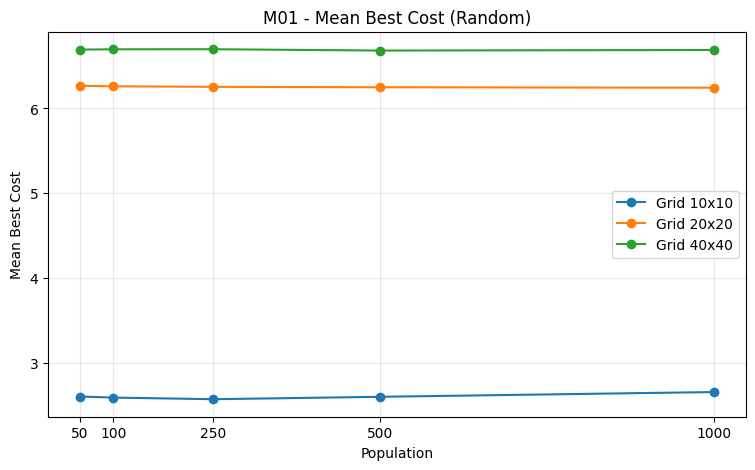

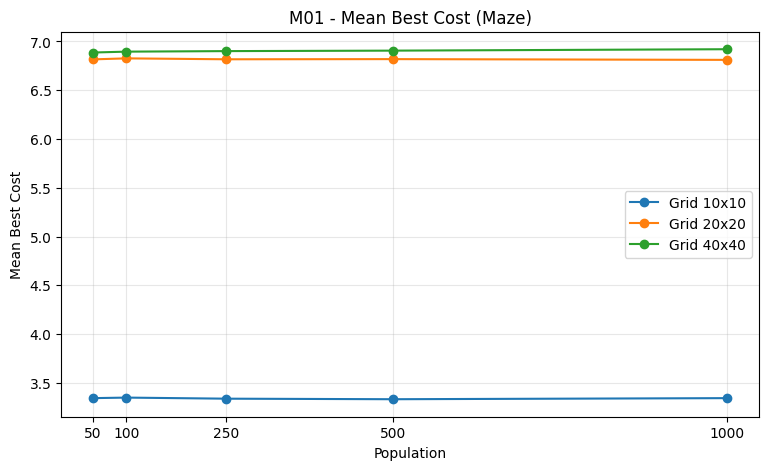

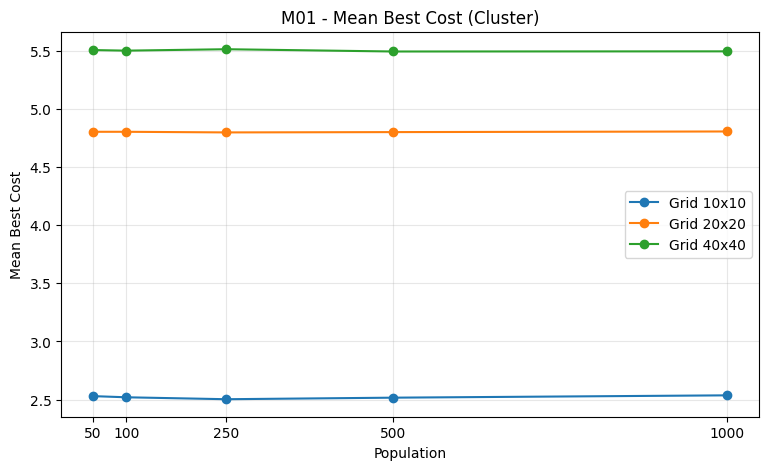

In [10]:
#avg cost berdasarkan populasi, ukuran peta dan jenis peta
summary_M01_size=(df_m01.groupby(["grid_rows", "population", "map_type"], as_index=False).agg( 
        mean_cost=("best_cost", "mean"),
        best_run=("best_cost", "min"),
        worst_run=("best_cost", "max"),
        std_cost=("best_cost", "std"),
        total_runs=("best_cost", "count")))
display(summary_M01_size)
#avg cost berdasarkan ukuran peta dan populasi di jenis random
table_random = (
    summary_M01_size[summary_M01_size["map_type"] == "Random"]
    .sort_values("grid_rows")
)

display(table_random)
#avg cost berdasarkan ukuran peta dan populasi di jenis maze
table_maze = (
    summary_M01_size[summary_M01_size["map_type"] == "Maze"]
    .sort_values("grid_rows")
)
#avg cost berdasarkan ukuran peta dan populasi di jenis cluster
display(table_maze)
table_cluster = (
    summary_M01_size[summary_M01_size["map_type"] == "Cluster"]
    .sort_values("grid_rows")
)

display(table_cluster)



map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = summary_M01_size[
        summary_M01_size["map_type"] == map_type
    ].copy()

    plt.figure(figsize=(9, 5))

    for grid_rows in sorted(data["grid_rows"].unique()):
        data_size = (
            data[data["grid_rows"] == grid_rows]
            .sort_values("population")
        )

        plt.plot(
            data_size["population"],
            data_size["mean_cost"],
            marker="o",
            label=f"Grid {grid_rows}x{grid_rows}"
        )

    plt.title(f"M01 - Mean Best Cost ({map_type})")
    plt.xlabel("Population")
    plt.ylabel("Mean Best Cost")
    plt.xticks(sorted(data["population"].unique()))
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

In [30]:
summary_M01_size["rank_mean_cost"] = (
    summary_M01_size
    .groupby(["grid_rows", "map_type"])["mean_cost"]
    .rank(method="average", ascending=True)
)
avg_rank_M01 = (
    summary_M01_size
    .groupby("population", as_index=False)
    .agg(
        avg_rank_mean=("rank_mean_cost", "mean"),
        avg_mean_cost=("mean_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_mean_cost", "count")
    )
    .sort_values(["avg_rank_mean", "avg_mean_cost"])
)
display(avg_rank_M01)
display(summary_M01_size)

,population,avg_rank_mean,avg_mean_cost,avg_std_cost,jumlah_kombinasi
3,500,2.222222,5.044066,0.073824,9
2,250,2.666667,5.043517,0.072738,9
4,1000,3.277778,5.055442,0.076966,9
0,50,3.333333,5.049641,0.082705,9
1,100,3.500000,5.048992,0.081411,9


,grid_rows,population,map_type,mean_cost,best_run,worst_run,std_cost,total_runs,rank_mean_cost,rank_std_cost
0,10,50,Cluster,2.530000,2.500000,2.700000,0.053498,30,4.0,5.0
1,10,50,Maze,3.344444,3.333333,3.500000,0.042285,30,3.5,3.0
2,10,50,Random,2.602183,2.416667,2.928571,0.167748,60,4.0,5.0
3,10,100,Cluster,2.520000,2.500000,2.600000,0.040684,30,3.0,3.0
4,10,100,Maze,3.350000,3.333333,3.500000,0.050855,30,5.0,5.0
5,10,100,Random,2.589683,2.416667,2.857143,0.157561,60,2.0,3.0
6,10,250,Cluster,2.503333,2.500000,2.600000,0.018257,30,1.0,1.0
7,10,250,Maze,3.338889,3.333333,3.500000,0.030429,30,2.0,2.0
8,10,250,Random,2.570238,2.416667,2.785714,0.155832,60,1.0,2.0
9,10,500,Cluster,2.516667,2.500000,2.600000,0.037905,30,2.0,2.0


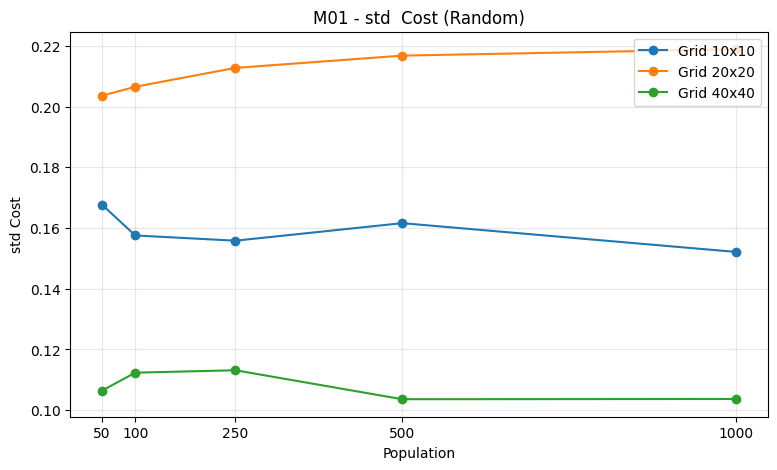

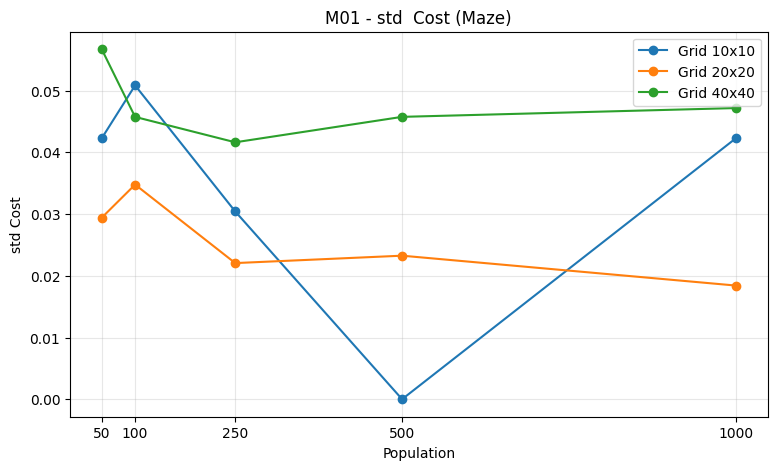

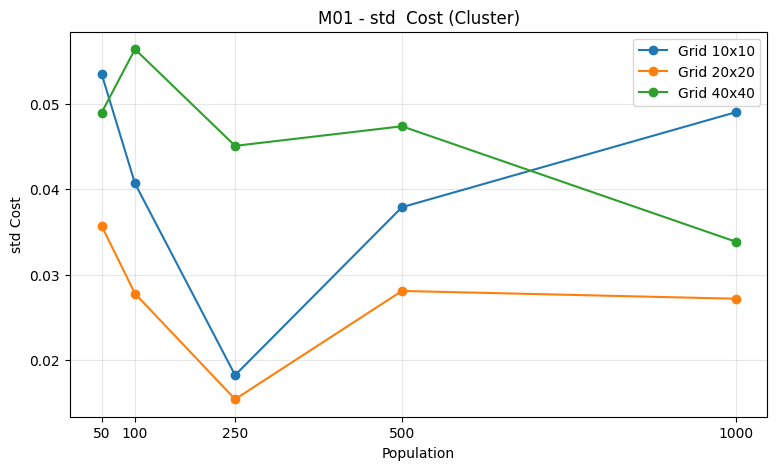

map_type               Cluster      Maze    Random
grid_rows population                              
10        50          0.053498  0.042285  0.167748
          100         0.040684  0.050855  0.157561
          250         0.018257  0.030429  0.155832
          500         0.037905  0.000000  0.161607
          1000        0.049013  0.042285  0.152132
20        50          0.035724  0.029416  0.203598
          100         0.027793  0.034783  0.206542
          250         0.015442  0.022061  0.212763
          500         0.028108  0.023261  0.216806
          1000        0.027197  0.018420  0.218916
40        50          0.048961  0.056718  0.106398
          100         0.056384  0.045750  0.112345
          250         0.045080  0.041635  0.113147
          500         0.047370  0.045758  0.103600
          1000        0.033872  0.047183  0.103676

   population  avg_rank_std  avg_std_cost  jumlah_kombinasi
2         250      2.111111      0.072738                 9
3         500      2.777778      0.073824                 9
4        1000      2.666667      0.076966                 9
1         100      3.555556      0.081411                 9
0          50      3.888889      0.082705                 9


In [28]:
map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = summary_M01_size[
        summary_M01_size["map_type"] == map_type
    ].copy()

    plt.figure(figsize=(9, 5))

    for grid_rows in sorted(data["grid_rows"].unique()):
        data_size = (
            data[data["grid_rows"] == grid_rows]
            .sort_values("population")
        )

        plt.plot(
            data_size["population"],
            data_size["std_cost"],
            marker="o",
            label=f"Grid {grid_rows}x{grid_rows}"
        )

    plt.title(f"M01 - std  Cost ({map_type})")
    plt.xlabel("Population")
    plt.ylabel("std Cost")
    plt.xticks(sorted(data["population"].unique()))
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

    
summary_Std_pivot = summary_M01_size.pivot(
    index=["grid_rows", "population"],
    columns="map_type",
    values="std_cost"
)
display(summary_Std_pivot)

summary_M01_size["rank_std_cost"] = (
    summary_M01_size
    .groupby(["grid_rows", "map_type"])["std_cost"]
    .rank(method="average", ascending=True)
)

avg_rank_M01_std = (
    summary_M01_size
    .groupby("population", as_index=False)
    .agg(
        avg_rank_std=("rank_std_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_std_cost", "count")
    )
    .sort_values(["avg_std_cost"])
)

print(avg_rank_M01_std)


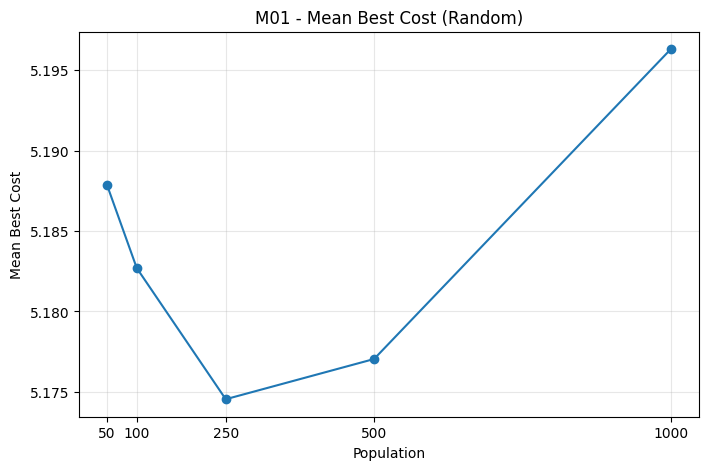

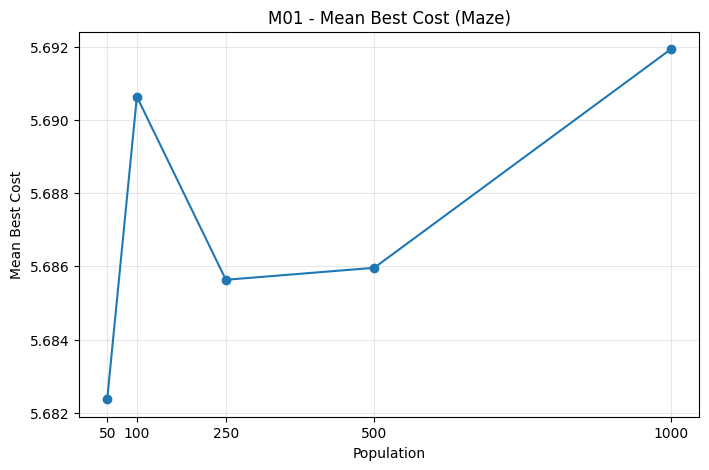

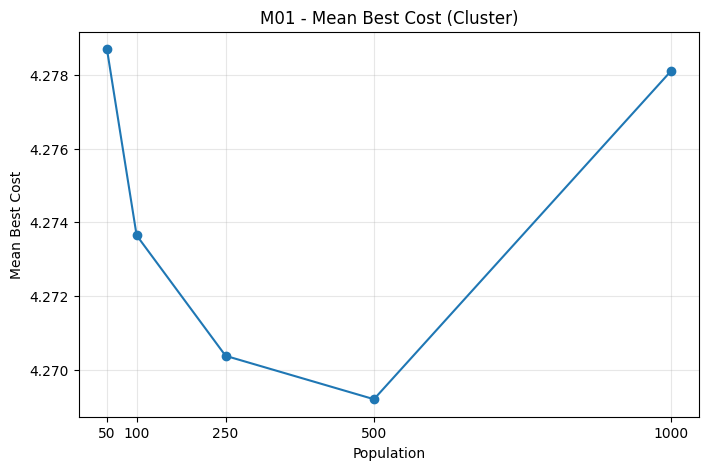

In [ ]:

map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = summary_M01[
        summary_M01["map_type"] == map_type
    ].sort_values("population")

    plt.figure(figsize=(8, 5))

    plt.plot(
        data["population"],
        data["mean_cost"],
        marker="o"
    )

    plt.title(f"M01 - Mean Best Cost ({map_type})")
    plt.xlabel("Population")
    plt.ylabel("Mean Best Cost")
    plt.xticks(data["population"])
    plt.grid(True, alpha=0.3)

    plt.show()

In [27]:
summary_M01_time=(df_m01.groupby(["grid_rows","population", "map_type"], as_index=False).agg(
        mean_execTime=("execution_time_ms", "mean"),
        best_execTime=("execution_time_ms", "min"),
        worst_execTime=("execution_time_ms", "max"),
        std_Time=("execution_time_ms", "std"),
        total_runs=("execution_time_ms", "count")
    ))
display(summary_M01_time)
avg_time_by_population_m01 = (
    summary_M01_time
    .groupby("population", as_index=False)
    .agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    )
    .sort_values("avg_execTime")
)
display(avg_time_by_population_m01)
summary_time_pivot = summary_M01_time.pivot(
    index=["grid_rows", "population"],
    columns="map_type",
    values="mean_execTime"
)
display(summary_Std_pivot)

avg_time_by_map = (
    summary_M01_time
    .groupby(["map_type", "population"], as_index=False)
    .agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    )
    .sort_values(["avg_execTime"])
)

print(avg_time_by_map)

,grid_rows,population,map_type,mean_execTime,best_execTime,worst_execTime,std_Time,total_runs
0,10,50,Cluster,29.066667,4,157,48.367083,30
1,10,50,Maze,14.100000,3,70,22.124023,30
2,10,50,Random,22.600000,3,95,26.964635,60
3,10,100,Cluster,26.233333,5,90,25.901249,30
4,10,100,Maze,21.900000,7,81,22.682744,30
5,10,100,Random,26.066667,6,117,28.684057,60
6,10,250,Cluster,27.400000,9,94,25.718100,30
7,10,250,Maze,26.466667,7,110,32.695812,30
8,10,250,Random,34.066667,9,107,28.236811,60
9,10,500,Cluster,39.733333,15,132,35.626350,30


,population,avg_execTime,avg_std_time,jumlah_kombinasi
0,50,311.894444,102.181668,9
1,100,345.457407,88.766366,9
2,250,405.338889,110.889188,9
3,500,601.462963,105.801754,9
4,1000,822.275926,80.564541,9


map_type               Cluster      Maze    Random
grid_rows population                              
10        50          0.053498  0.042285  0.167748
          100         0.040684  0.050855  0.157561
          250         0.018257  0.030429  0.155832
          500         0.037905  0.000000  0.161607
          1000        0.049013  0.042285  0.152132
20        50          0.035724  0.029416  0.203598
          100         0.027793  0.034783  0.206542
          250         0.015442  0.022061  0.212763
          500         0.028108  0.023261  0.216806
          1000        0.027197  0.018420  0.218916
40        50          0.048961  0.056718  0.106398
          100         0.056384  0.045750  0.112345
          250         0.045080  0.041635  0.113147
          500         0.047370  0.045758  0.103600
          1000        0.033872  0.047183  0.103676

   map_type  population  avg_execTime  avg_std_time  jumlah_kombinasi
5      Maze          50    287.366667    119.534984                 3
6      Maze         100    315.266667    122.099010                 3
10   Random          50    321.561111     95.939441                 3
0   Cluster          50    326.755556     91.070579                 3
11   Random         100    357.461111     66.830834                 3
1   Cluster         100    363.644444     77.369253                 3
2   Cluster         250    373.266667    129.670401                 3
7      Maze         250    396.177778     88.284730                 3
12   Random         250    446.572222    114.712434                 3
3   Cluster         500    580.544444    109.304518                 3
13   Random         500    603.588889     82.117365                 3
8      Maze         500    620.255556    125.983380                 3
9      Maze        1000    792.777778     69.536171                 3
4   Cluster        1